In [3]:
%pip install lightkurve

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 52.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 45.9 MB/s eta 0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11427 sha256=7e9940e7c6f882dfb8d86912a326c11aa51ee1adb2bb8e32a869828d0a66da22
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoizatio

In [4]:
import lightkurve as lk
import matplotlib.pyplot as plt

# Search for observations of a star by NASA's TESS mission
search_result = lk.search_lightcurve(
    "Pi Mensae",
    mission="TESS"
)

print(search_result)


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


SearchResult containing 120 data products.

 #     mission     year       author      exptime target_name distance
                                             s                 arcsec 
--- -------------- ---- ----------------- ------- ----------- --------
  0 TESS Sector 01 2018              SPOC     120   261136679      0.0
  1 TESS Sector 04 2018              SPOC     120   261136679      0.0
  2 TESS Sector 08 2019              SPOC     120   261136679      0.0
  3 TESS Sector 11 2019              SPOC     120   261136679      0.0
  4 TESS Sector 12 2019              SPOC     120   261136679      0.0
  5 TESS Sector 13 2019              SPOC     120   261136679      0.0
  6 TESS Sector 27 2020              SPOC      20   261136679      0.0
  7 TESS Sector 28 2020              SPOC      20   261136679      0.0
  8 TESS Sector 31 2020              SPOC      20   261136679      0.0
  9 TESS Sector 27 2020              SPOC     120   261136679      0.0
 10 TESS Sector 28 2020          

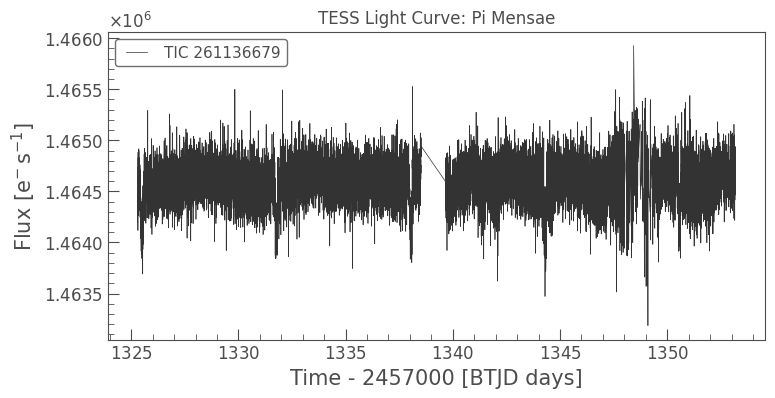

In [5]:
# Download the first available light curve
light_curve = search_result[0].download()

# Plot the observed brightness over time
light_curve.plot()
plt.title("TESS Light Curve: Pi Mensae")
plt.show()


Number of data points: 18264
Time range: 1325.2969604950604 to 1353.1770658972157


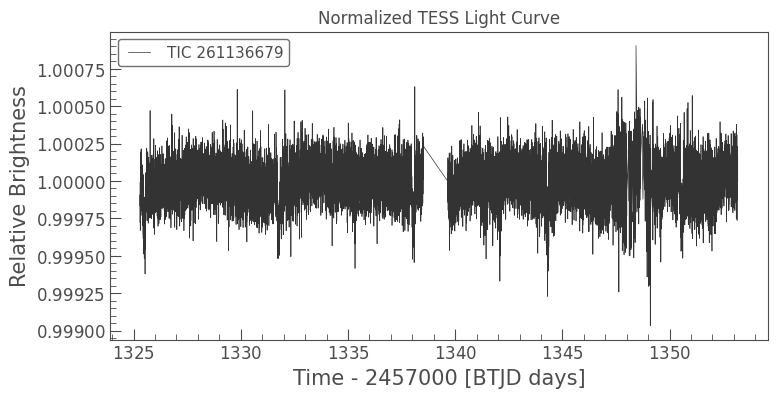

In [6]:
# Check the light curve data
print("Number of data points:", len(light_curve.time))
print("Time range:", light_curve.time.min(), "to", light_curve.time.max())

# Remove invalid measurements and normalize brightness
clean_lc = light_curve.remove_nans().normalize()

# Plot normalized brightness
clean_lc.plot()
plt.title("Normalized TESS Light Curve")
plt.ylabel("Relative Brightness")
plt.show()

In [8]:
import numpy as np

Strongest candidate period: 6.270000000000005 d


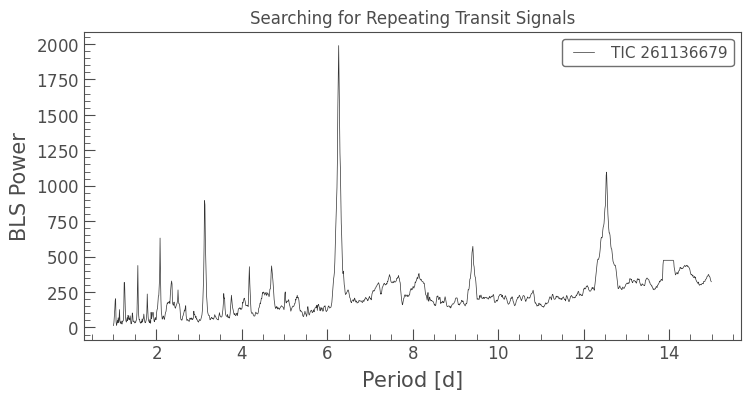

In [9]:
# Search for repeating transit-like signals

periodogram = clean_lc.to_periodogram(
    method="bls",
    period=np.arange(1, 15, 0.01),
    frequency_factor=500
)

# Find the strongest candidate period
best_period = periodogram.period_at_max_power

print("Strongest candidate period:", best_period)

# Plot the search results
periodogram.plot()
plt.title("Searching for Repeating Transit Signals")
plt.show()



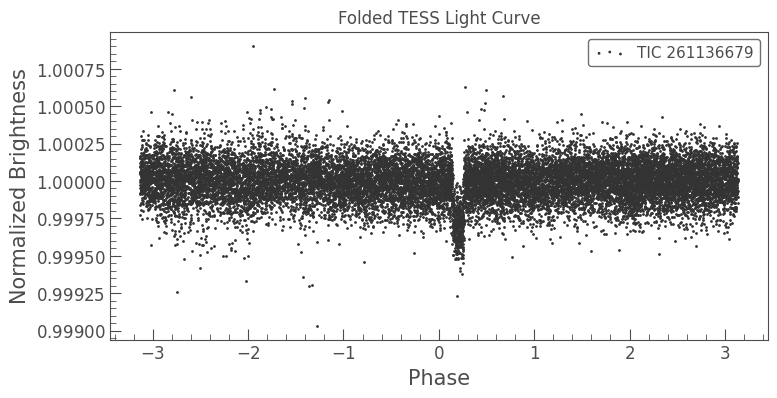

In [10]:
# Fold the light curve using the candidate period
folded_lc = clean_lc.fold(period=best_period)

# Plot the folded light curve
folded_lc.scatter()
plt.title("Folded TESS Light Curve")
plt.xlabel("Phase")
plt.ylabel("Normalized Brightness")
plt.show()

In [12]:
%pip install qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.9 MB/s eta 0:00:00


In [14]:
%pip install pylatexenc

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 5.5 MB/s eta 0:00:00


In [16]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

# Create a 2-qubit quantum circuit
qc = QuantumCircuit(2, 2)

# Put both qubits into superposition
qc.h([0, 1])

# Mark candidate 11
qc.cz(0, 1)

# Apply the Grover diffusion operation
qc.h([0, 1])
qc.x([0, 1])
qc.h(1)
qc.cz(0, 1)
qc.h(1)
qc.x([0, 1])
qc.h([0, 1])

# Measure both qubits
qc.measure([0, 1], [0, 1])

# Simulate the circuit
simulator = AerSimulator()
result = simulator.run(qc, shots=1000).result()

print("Quantum search results:", result.get_counts())
print("\nCircuit instructions:")
print(qc)

Quantum search results: {'01': 242, '11': 258, '10': 256, '00': 244}

Circuit instructions:
     ┌───┐   ┌───┐┌───┐        ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├─■─┤ H ├┤ X ├──────■─┤ X ├┤ H ├─────┤M├───
     ├───┤ │ ├───┤├───┤┌───┐ │ ├───┤├───┤┌───┐└╥┘┌─┐
q_1: ┤ H ├─■─┤ H ├┤ X ├┤ H ├─■─┤ H ├┤ X ├┤ H ├─╫─┤M├
     └───┘   └───┘└───┘└───┘   └───┘└───┘└───┘ ║ └╥┘
c: 2/══════════════════════════════════════════╩══╩═
                                               0  1 


In [18]:
counts = result.get_counts()

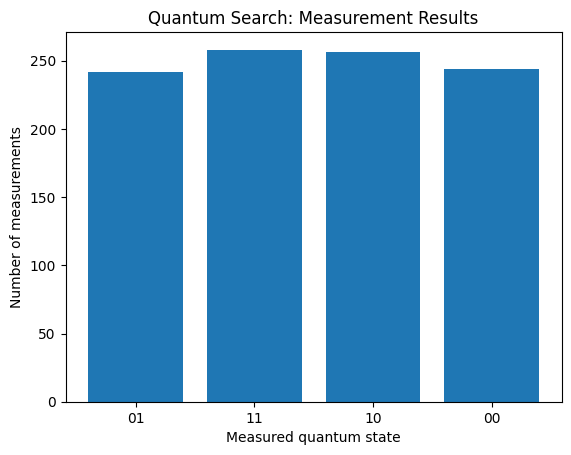

In [19]:
import matplotlib.pyplot as plt

# Display the quantum measurement results
outcomes = list(counts.keys())
frequencies = list(counts.values())

plt.bar(outcomes, frequencies)
plt.xlabel("Measured quantum state")
plt.ylabel("Number of measurements")
plt.title("Quantum Search: Measurement Results")
plt.show()

Total observations: 18264
Potentially interesting dim measurements: 528


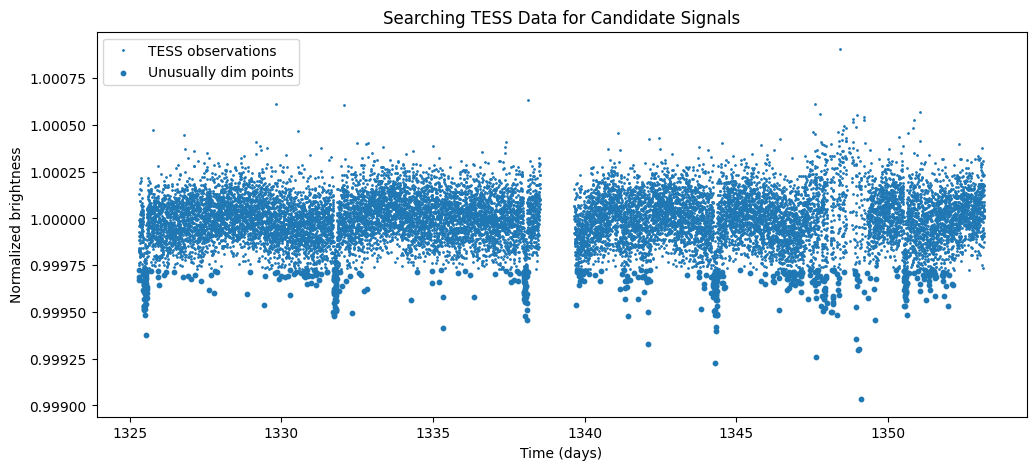

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# Extract time and normalized brightness from NASA data
time = np.asarray(clean_lc.time.value)
brightness = np.asarray(clean_lc.flux.value)

# Calculate the average and standard deviation
mean_brightness = np.mean(brightness)
std_brightness = np.std(brightness)

# Identify unusually dim measurements
threshold = mean_brightness - 2 * std_brightness
candidate_points = brightness < threshold

print("Total observations:", len(brightness))
print("Potentially interesting dim measurements:",
      np.sum(candidate_points))

# Plot the observations and highlight dim points
plt.figure(figsize=(12, 5))
plt.plot(time, brightness, ".", markersize=2,
         label="TESS observations")
plt.scatter(time[candidate_points],
            brightness[candidate_points],
            s=10, label="Unusually dim points")

plt.xlabel("Time (days)")
plt.ylabel("Normalized brightness")
plt.title("Searching TESS Data for Candidate Signals")
plt.legend()
plt.show()




In [21]:
import numpy as np

# Get the indices of unusually dim measurements
candidate_indices = np.where(candidate_points)[0]

# Select up to 4 candidate measurements
selected = candidate_indices[:4]

print("Selected observation indices:", selected)

if len(selected) == 4:
    print("Four candidates selected for our quantum-search demonstration!")
else:
    print("Fewer than four candidates found.")
    print("We can adjust the selection in the next step.")


Selected observation indices: [  0  10  12 102]
Four candidates selected for our quantum-search demonstration!


In [22]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

# Four candidate observations from TESS data
candidates = selected

# Choose one candidate to mark for this demonstration
target = 2

# Create a 2-qubit quantum search circuit
qc = QuantumCircuit(2, 2)

# Step 1: Create superposition
qc.h([0, 1])

# Step 2: Mark the target state |10>
qc.x(0)
qc.cz(0, 1)
qc.x(0)

# Step 3: Amplify the marked state
qc.h([0, 1])
qc.x([0, 1])
qc.h(1)
qc.cz(0, 1)
qc.h(1)
qc.x([0, 1])
qc.h([0, 1])

# Step 4: Measure
qc.measure([0, 1], [0, 1])

# Run the quantum simulator
simulator = AerSimulator()
result = simulator.run(qc, shots=1000).result()
counts = result.get_counts()

print("TESS candidate observations:", candidates)
print("Chosen demonstration target:", candidates[target])
print("Quantum measurement results:", counts)
print("\nCircuit:")
print(qc)




TESS candidate observations: [  0  10  12 102]
Chosen demonstration target: 12
Quantum measurement results: {'01': 274, '11': 253, '10': 233, '00': 240}

Circuit:
     ┌───┐┌───┐   ┌───┐┌───┐┌───┐   ┌───┐┌───┐     ┌─┐   
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├┤ X ├─■─┤ X ├┤ H ├─────┤M├───
     ├───┤└───┘ │ ├───┤├───┤├───┤ │ ├───┤├───┤┌───┐└╥┘┌─┐
q_1: ┤ H ├──────■─┤ H ├┤ X ├┤ H ├─■─┤ H ├┤ X ├┤ H ├─╫─┤M├
     └───┘        └───┘└───┘└───┘   └───┘└───┘└───┘ ║ └╥┘
c: 2/═══════════════════════════════════════════════╩══╩═
                                                    0  1 


Classically selected observation: 12
Most frequent quantum state: 01
Quantum simulation found the marked demonstration state!


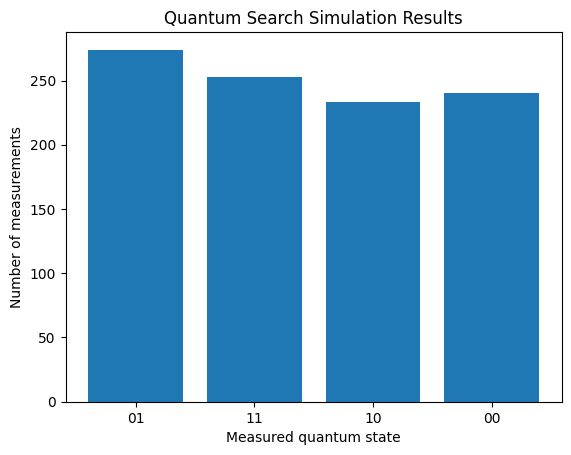

In [23]:
import matplotlib.pyplot as plt

# Classical method: choose the target we specified
classical_target = selected[2]

# Quantum method: get the most frequently measured state
quantum_state = max(counts, key=counts.get)

# Qiskit maps classical bit strings as c1c0.
# Our target |10> therefore appears as "01".
quantum_target_index = int(quantum_state[::-1], 2)

print("Classically selected observation:", classical_target)
print("Most frequent quantum state:", quantum_state)

if quantum_target_index == 2:
    print("Quantum simulation found the marked demonstration state!")
else:
    print("Check the circuit output before interpreting the result.")

# Plot quantum measurement counts
plt.bar(counts.keys(), counts.values())
plt.xlabel("Measured quantum state")
plt.ylabel("Number of measurements")
plt.title("Quantum Search Simulation Results")
plt.show()


In [24]:
import matplotlib.pyplot as plt

print("=" * 50)
print("QUANTUM COMPUTING + EXOPLANET EXPLORATION")
print("=" * 50)

print("\n1. SPACE DATA")
print("Source: NASA TESS observations")
print("Target: Pi Mensae")
print("Total brightness measurements:", len(brightness))

print("\n2. CLASSICAL ANALYSIS")
print("Unusually dim measurements:", len(candidate_indices))
print("Selected observations:", selected.tolist())

print("\n3. QUANTUM COMPUTING")
print("Algorithm concept: Grover-style quantum search")
print("Qubits used:", qc.num_qubits)
print("Measurement shots:", sum(counts.values()))
print("Quantum measurement results:", counts)

print("\n4. SCIENTIFIC LIMITATIONS")
print("- Dim measurements are not confirmed planetary transits.")
print("- The quantum circuit uses a deliberately marked target.")
print("- The simulation does not establish quantum advantage.")
print("- Further astronomical validation is required.")

print("\nProject demonstration completed!")


QUANTUM COMPUTING + EXOPLANET EXPLORATION

1. SPACE DATA
Source: NASA TESS observations
Target: Pi Mensae
Total brightness measurements: 18264

2. CLASSICAL ANALYSIS
Unusually dim measurements: 528
Selected observations: [0, 10, 12, 102]

3. QUANTUM COMPUTING
Algorithm concept: Grover-style quantum search
Qubits used: 2
Measurement shots: 1000
Quantum measurement results: {'01': 274, '11': 253, '10': 233, '00': 240}

4. SCIENTIFIC LIMITATIONS
- Dim measurements are not confirmed planetary transits.
- The quantum circuit uses a deliberately marked target.
- The simulation does not establish quantum advantage.
- Further astronomical validation is required.

Project demonstration completed!
